# 04. Multiple Linear Regression & Feature Scaling
### Vectorized Gradient Descent with Multiple Features (Qatar Real Estate Context)

In the real world, predictions rarely depend on just one feature. For example, the rent of an apartment in Doha or Lusail depends not only on its **size**, but also on the number of **bedrooms** and its **distance to the nearest Doha Metro station**.

---

### The Multiple Linear Regression Model
Given $m$ examples and $n$ features:
- $\mathbf{X} \in \mathbb{R}^{m \times n}$ is the feature matrix.
- $\mathbf{w} \in \mathbb{R}^n$ is the weight vector (one weight per feature).
- $b \in \mathbb{R}$ is the scalar bias (intercept).

The vectorized prediction is:

$$\hat{\mathbf{y}} = \mathbf{X} \mathbf{w} + b$$

where $\hat{\mathbf{y}} \in \mathbb{R}^m$ is the vector of predictions for all apartments.

---

### Dataset: Doha & Lusail Apartments
We use `data/doha_apartment_features.csv`, featuring:
1. `area_m2`: Apartment size in square meters ($55$ to $240\ m^2$)
2. `bedrooms`: Number of bedrooms ($1$ to $4$)
3. `distance_to_metro_km`: Distance to nearest Doha Metro station in kilometers ($0.4$ to $4.5$ km)
4. `monthly_rent_qar`: Target monthly rent in QAR ($4,700$ to $15,200$ QAR)

In [10]:
# Step 1: Import core scientific libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

## Section 1: Loading & Inspecting the Multi-Feature Dataset

Let's load the dataset from `data/doha_apartment_features.csv` and inspect the summary statistics.

In [11]:
# Step 2: Load multi-feature dataset
df = pd.read_csv('data/doha_apartment_features.csv')

print(f"Total listings: {len(df)}")
print("\nDataset preview:")
display(df.head()) if 'display' in globals() else print(df.head())

print("\nFeature summary statistics:")
display(df.describe().round(1)) if 'display' in globals() else print(df.describe().round(1))

Total listings: 18

Dataset preview:
   area_m2  bedrooms  distance_to_metro_km  monthly_rent_qar
0       55         1                   0.4              4900
1       65         1                   1.8              4700
2       75         1                   0.6              5800
3       85         2                   2.5              6200
4       95         2                   0.8              7400

Feature summary statistics:
       area_m2  bedrooms  distance_to_metro_km  monthly_rent_qar
count     18.0      18.0                  18.0              18.0
mean     141.7       2.7                   1.7            9438.9
std       56.1       1.1                   1.2            3195.2
min       55.0       1.0                   0.4            4700.0
25%       97.5       2.0                   0.8            7175.0
50%      140.0       3.0                   1.4            9350.0
75%      182.5       3.8                   2.2           11925.0
max      240.0       4.0                   4.5  

## Section 2: Why Feature Scaling is Essential

Notice the dramatic difference in scale between our features:
- `area_m2` ranges from $55$ to $240$ (scale: hundreds).
- `bedrooms` ranges from $1$ to $4$ (scale: single digits).
- `distance_to_metro_km` ranges from $0.4$ to $4.5$ (scale: decimals / units).

### The Geometric Consequence:
When features have vastly different scales:
1. The cost function forms a **long, narrow valley** rather than a round bowl.
2. The gradient for large features (like area) is enormous, while the gradient for small features (like bedrooms) is tiny.
3. Gradient descent oscillates wildly back and forth across the narrow canyon walls, requiring an extremely small learning rate and thousands of extra steps to converge.

### The Solution: Z-Score Standardization
We transform each feature to have **zero mean** ($\mu = 0$) and **unit standard deviation** ($\sigma = 1$):

$$x_{\text{norm}} = \frac{x - \mu}{\sigma}$$

where $\mu$ is the mean of the feature column and $\sigma$ is its standard deviation.

In [12]:
# Step 3: Implement Z-Score standardization

def standardize_features(X):
    """
    Standardize feature matrix X to mean=0 and std=1 column-wise.
    
    Parameters:
        X (ndarray): Matrix of shape (m, n)
        
    Returns:
        X_norm (ndarray): Standardized feature matrix
        mu (ndarray): Column means of shape (n,)
        sigma (ndarray): Column standard deviations of shape (n,)
    """
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    # replaces zero standard deviations with 1.0 
    # to prevent division by zero during normalization.
    sigma[sigma == 0] = 1.0
    X_norm = (X - mu) / sigma
    return X_norm, mu, sigma

# Prepare raw feature matrix X and target vector y
feature_cols = ['area_m2', 'bedrooms', 'distance_to_metro_km']
X_raw = df[feature_cols].values.astype(float)
y = df['monthly_rent_qar'].values.astype(float)

# Standardize features
X_norm, mu_X, sigma_X = standardize_features(X_raw)

print(f"Original Feature Means : {mu_X.round(2)}")
print(f"Original Feature Stds  : {sigma_X.round(2)}")
print(f"\nStandardized X preview (first 5 rows):\n{X_norm[:5].round(3)}")

Original Feature Means : [141.67   2.67   1.68]
Original Feature Stds  : [54.49  1.05  1.16]

Standardized X preview (first 5 rows):
[[-1.59  -1.581 -1.103]
 [-1.407 -1.581  0.1  ]
 [-1.223 -1.581 -0.931]
 [-1.04  -0.632  0.702]
 [-0.856 -0.632 -0.759]]


## Section 3: Vectorized Cost & Gradient Formulas

With matrix notation, formulas become elegant, clear, and fast:

### 1. Model Prediction (Vector of shape $(m,)$):
$$\hat{\mathbf{y}} = \mathbf{X} \mathbf{w} + b$$

### 2. Error Vector (shape $(m,)$):
$$\mathbf{e} = \hat{\mathbf{y}} - \mathbf{y}$$

### 3. Mean Squared Error Cost (Divided by $m$):
$$J(\mathbf{w}, b) = \frac{1}{m} \|\mathbf{e}\|^2 = \frac{1}{m} \sum_{i=1}^{m} e_i^2$$

### 4. Vectorized Gradients (with factor $\frac{2}{m}$):
$$\frac{\partial J}{\partial \mathbf{w}} = \frac{2}{m} \mathbf{X}^T \mathbf{e} \quad \in \mathbb{R}^n$$
$$\frac{\partial J}{\partial b} = \frac{2}{m} \sum_{i=1}^{m} e_i \quad \in \mathbb{R}$$

In [13]:
# Step 4: Vectorized cost and gradient functions

def compute_cost(X, y, w, b):
    """Compute MSE cost J(w, b) = (1/m) * sum((X@w + b - y)^2)."""
    m = len(y)
    y_hat = X @ w + b  # Matrix-vector product (m, n) @ (n,) -> (m,)
    errors = y_hat - y
    return (1 / m) * np.sum(errors ** 2)

def compute_gradient(X, y, w, b):
    """
    Compute gradients w.r.t weight vector w and scalar bias b.
    """
    m = len(y)
    y_hat = X @ w + b
    errors = y_hat - y
    
    # Vectorized gradient: (2/m) * (X.T @ errors) -> shape (n,)
    dj_dw = (2 / m) * (X.T @ errors)
    # Bias gradient: (2/m) * sum(errors)
    dj_db = (2 / m) * np.sum(errors)
    
    return dj_dw, dj_db

## Section 4: Training Vectorized Gradient Descent

Now let's implement the gradient descent loop. We initialize $\mathbf{w} = \mathbf{0} \in \mathbb{R}^n$ and $b = 0$.

In [14]:
# Step 5: Multi-variable gradient descent loop
def gradient_descent(X, y, alpha=0.03, num_iters=800):
    """
    Batch gradient descent for multiple linear regression.
    """
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    cost_history = []
    
    for _ in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        cost_history.append(compute_cost(X, y, w, b))
        
    return w, b, cost_history

# Train model on standardized features
w_opt, b_opt, cost_hist_scaled = gradient_descent(X_norm, y, alpha=0.03, num_iters=600)

print("Training Complete on Standardized Features!")
print(f"Learned Bias (b): {b_opt:,.2f} QAR")
for col, weight in zip(feature_cols, w_opt):
    print(f"Weight for {col:<22}: {weight:,.2f}")

Training Complete on Standardized Features!
Learned Bias (b): 9,438.89 QAR
Weight for area_m2               : 2,455.02
Weight for bedrooms              : 751.14
Weight for distance_to_metro_km  : -467.50


## Section 5: Interpreting the Learned Model Parameters

Because our features are standardized to the same scale, we can directly compare the magnitude and sign of the weights to understand what drives rental prices in Qatar:
1. **$w_{\text{area}} > 0$ (+QAR):** Area has the largest positive impact on rent.
2. **$w_{\text{bedrooms}} > 0$ (+QAR):** Additional bedrooms increase rent independently of area.
3. **$w_{\text{distance\_to\_metro}} < 0$ (-QAR):** Distance to the metro has a **negative** weight! Each additional kilometer away from a Doha Metro station decreases monthly rent. Proximity to transit commands a clear premium in Qatar!

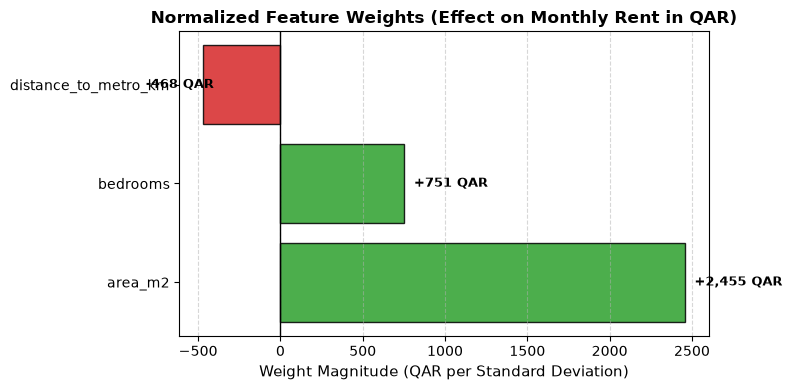

In [15]:
# Step 7: Bar plot of feature weights
plt.figure(figsize=(8, 4))
colors = ['#2ca02c' if w > 0 else '#d62728' for w in w_opt]
bars = plt.barh(feature_cols, w_opt, color=colors, edgecolor='black', alpha=0.85)

plt.axvline(0, color='black', linewidth=1)
plt.title('Normalized Feature Weights (Effect on Monthly Rent in QAR)', fontsize=12, fontweight='bold')
plt.xlabel('Weight Magnitude (QAR per Standard Deviation)', fontsize=11)

# Annotate values on bars
for bar, w in zip(bars, w_opt):
    x_pos = w + (60 if w > 0 else -350)
    plt.text(x_pos, bar.get_y() + bar.get_height()/2, f"{w:+,.0f} QAR", 
             va='center', fontsize=9, fontweight='bold')

plt.grid(True, linestyle='--', alpha=0.5, axis='x')
plt.tight_layout()
plt.show()

## Section 6: Making Predictions on New Doha Apartments

To predict the rent of a new apartment, we must:
1. Normalize the new apartment's features using the **exact same** $\boldsymbol{\mu}$ and $\boldsymbol{\sigma}$ computed from the training data!
2. Apply the formula: $\hat{y} = \mathbf{x}_{\text{new, norm}} \cdot \mathbf{w} + b$

In [16]:
# Step 8: Predict on new listings
new_apartments = np.array([
    [70,  1, 0.5],   # 70 m², 1 bed, 0.5 km to Metro (Near Metro Studio/1-bed)
    [120, 2, 1.2],   # 120 m², 2 bed, 1.2 km to Metro (Typical 2-bed)
    [190, 3, 3.5]    # 190 m², 3 bed, 3.5 km to Metro (Spacious family unit, farther out)
])

# Normalize using training set statistics
new_apartments_norm = (new_apartments - mu_X) / sigma_X

# Compute predictions
predicted_rents = new_apartments_norm @ w_opt + b_opt

print("Rent Predictions for New Listings in Doha:")
print("-" * 65)
for raw, rent in zip(new_apartments, predicted_rents):
    print(f"Area: {raw[0]:3.0f} m² | Beds: {raw[1]:1.0f} | Metro Dist: {raw[2]:3.1f} km  -->  Rent: {rent:,.0f} QAR")

Rent Predictions for New Listings in Doha:
-----------------------------------------------------------------
Area:  70 m² | Beds: 1 | Metro Dist: 0.5 km  -->  Rent: 5,498 QAR
Area: 120 m² | Beds: 2 | Metro Dist: 1.2 km  -->  Rent: 8,182 QAR
Area: 190 m² | Beds: 3 | Metro Dist: 3.5 km  -->  Rent: 11,124 QAR


## Section 8: Key Takeaways

1. **Matrix Vectorization:** With $\hat{\mathbf{y}} = \mathbf{X}\mathbf{w} + b$ and $\frac{\partial J}{\partial \mathbf{w}} = \frac{2}{m} \mathbf{X}^T \mathbf{e}$, we compute predictions and gradients in single matrix operations.
2. **Feature Scaling is Essential:** Standardization transforms distorted elliptical cost surfaces into circular shapes, accelerating gradient descent.
3. **Save Normalization Statistics:** Always normalize future test inputs using training $\boldsymbol{\mu}$ and $\boldsymbol{\sigma}$ (never recompute statistics on test samples).
4. **Next Step:** In Notebook 05, we explore the industry-standard implementation using **Scikit-Learn** and master regression evaluation metrics.